Estimated μ (mean): 9.40
Estimated σ² (variance): 7.86


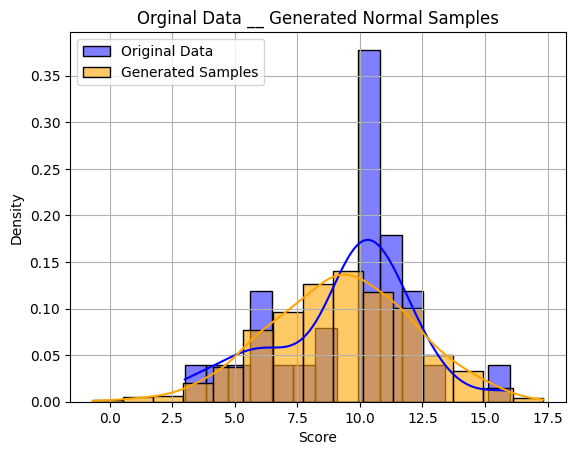

- Posterior Mean (μ_post): 9.55
- Posterior Variance (σ²_post): 1.04


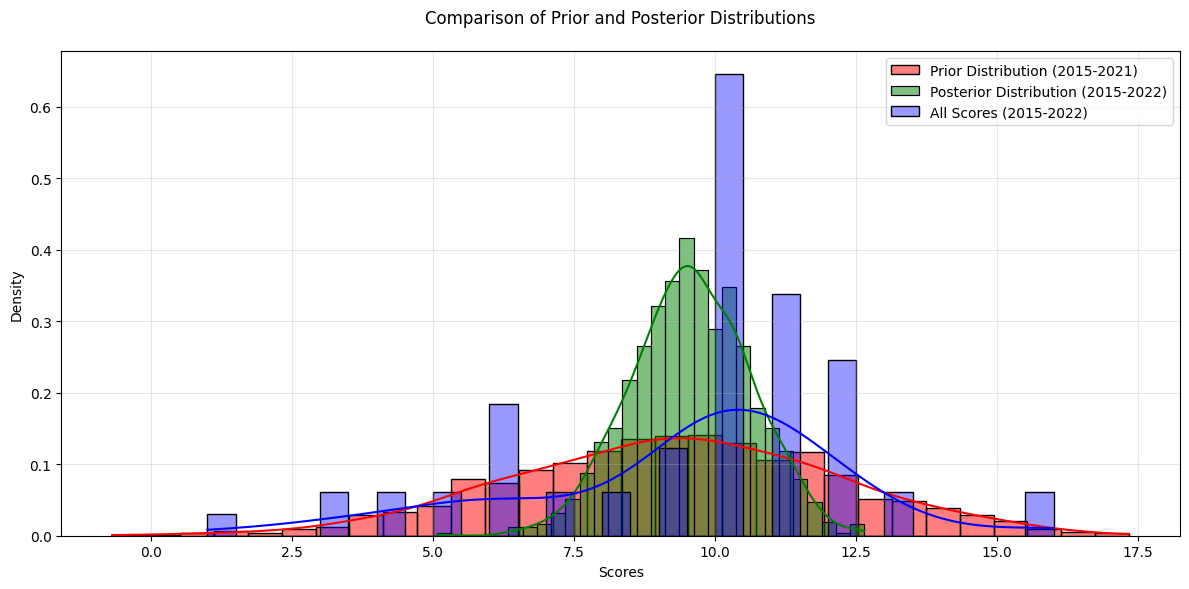

θ₁: Posterior Mean = 8.91, Posterior Variance = 1.38
θ₀: Posterior Mean = 10.77, Posterior Variance = 2.74


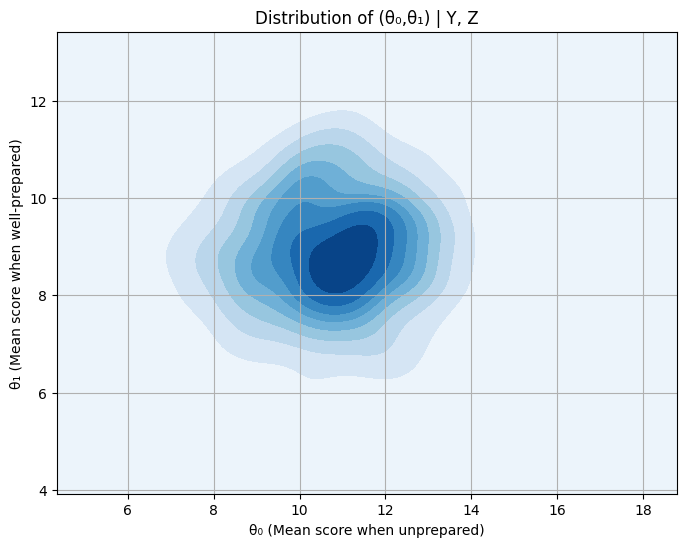

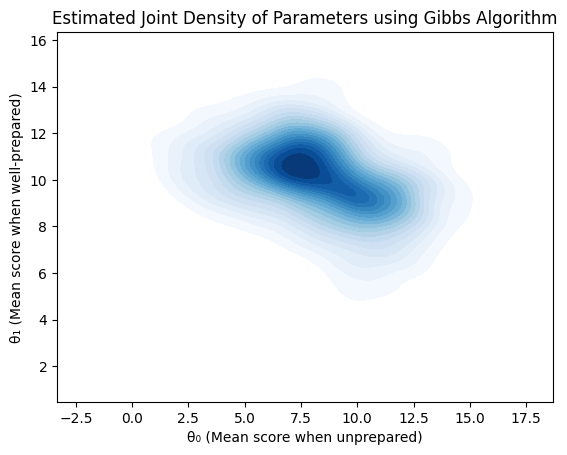

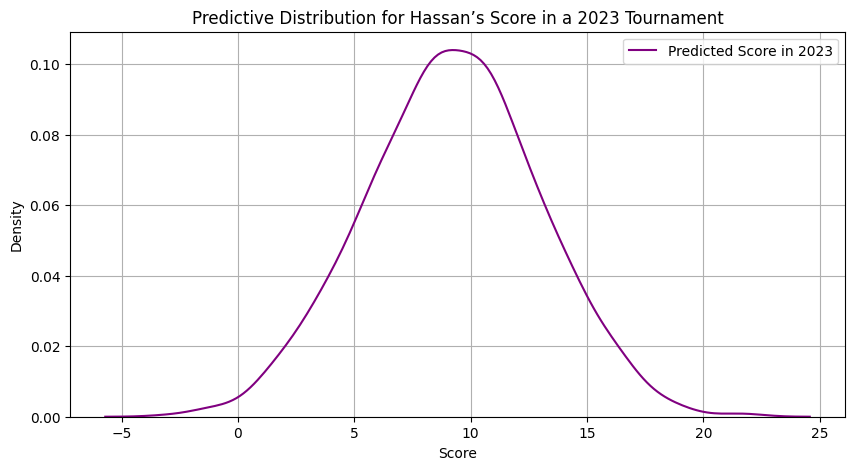

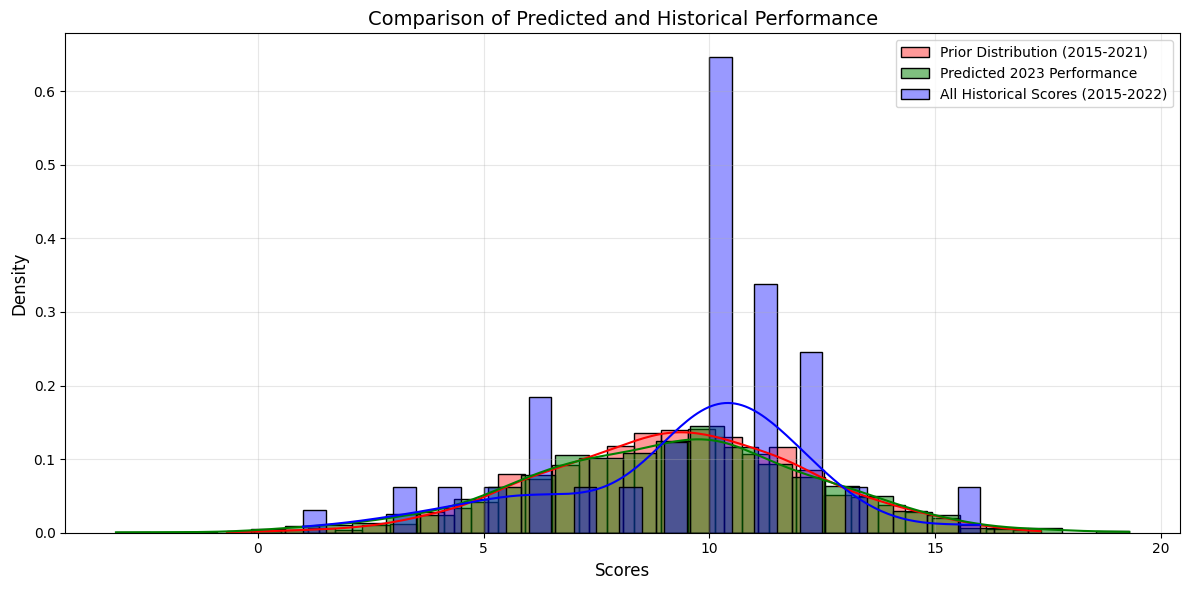

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

#step 1:

prior_scores = [
    3, 9, 6, 6, 16, 6, 8, 10, 9, 12, 10, 9, 13, 6, 10, 7, 10, 4, 11, 11,
    10, 4, 10, 10, 12, 10, 13, 12, 10, 12, 11, 10, 11, 10, 10, 6, 16, 11, 11, 10,
    10, 11, 5, 11, 5, 9, 10, 10, 10, 10, 3, 7, 12, 11, 6, 8, 10, 12
]
prior_mu = np.mean(prior_scores)
prior_sigma = np.std(prior_scores, ddof=1)
print(f"Estimated μ (mean): {prior_mu:.2f}")
print(f"Estimated σ² (variance): {prior_sigma**2:.2f}")
generated_samples = np.random.normal(prior_mu, prior_sigma, 1000)
sns.histplot(prior_scores, kde=True, stat="density", bins=15, label='Original Data', color='blue')
sns.histplot(generated_samples, kde=True, stat="density", bins=15, label='Generated Samples', color='orange', alpha=0.6)

plt.title("Orginal Data __ Generated Normal Samples")
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

#step 2:

def bayesian_analysis(prior_mu, prior_sigma2, scores_2022, lambda_val=8.4):
    n = len(scores_2022)
    y_bar = np.mean(scores_2022)

    # Posterior calculations
    sigma2_post = 1 / (n / lambda_val + 1 / prior_sigma2)
    mu_post = sigma2_post * (n * y_bar / lambda_val + prior_mu / prior_sigma2)
    print(f"- Posterior Mean (μ_post): {mu_post:.2f}")
    print(f"- Posterior Variance (σ²_post): {sigma2_post:.2f}")
    posterior_samples = np.random.normal(mu_post, np.sqrt(sigma2_post), 1000)
    return posterior_samples, mu_post, sigma2_post

def compare_distributions(prior_samples, posterior_samples, all_scores):
    plt.figure(figsize=(12, 6))
    # Plot prior distribution (from step 1)
    sns.histplot(prior_samples, bins=30, kde=True, color='red', stat='density', label='Prior Distribution (2015-2021)')

    # Plot posterior distribution
    sns.histplot(posterior_samples, bins=30, kde=True, color='green', stat='density', label='Posterior Distribution (2015-2022)')

    # Plot all empirical data
    sns.histplot(all_scores, bins=30, kde=True, color='blue', stat='density', label='All Scores (2015-2022)', alpha=0.4)

    plt.title("Comparison of Prior and Posterior Distributions", pad=20)
    plt.xlabel("Scores")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

scores_2022 = np.array([11, 12, 12, 1, 10, 11, 10])
posterior_samples, mu_post, sigma2_post = bayesian_analysis( prior_mu, prior_sigma**2, scores_2022)
compare_distributions(generated_samples, posterior_samples, np.concatenate([prior_scores, scores_2022]))

#step 3:

import numpy as np
from scipy.stats import norm, binom
import matplotlib.pyplot as plt
import seaborn as sns

class BayesianWrestlingModel:
    def __init__(self, historical_scores, p_prepared=0.7, lambda_fixed=8.4):
        import numpy as np
        self.p = p_prepared
        self.lambda_fixed = lambda_fixed

        # Calculate prior parameters from historical data
        self.mu_prior = np.mean(historical_scores)
        self.sigma2_prior = np.var(historical_scores, ddof=1)

        # 2022 match scores
        self.Y2022 = np.array([11, 12, 12, 1, 10, 11, 10])
        self.n = len(self.Y2022)

    def analyze_known_preparation(self):
        import numpy as np
        from scipy.stats import norm, binom
        import matplotlib.pyplot as plt
        import seaborn as sns
        # Simulate preparation status
        Z = binom.rvs(1, self.p, size=self.n)

        Y1 = self.Y2022[Z == 1]
        Y0 = self.Y2022[Z == 0]
        Y1_bar = np.mean(Y1)
        Y0_bar = np.mean(Y0)

        # Calculate posterior parameters for both states
        sigma2_theta1 = 1 / (len(Y1) / self.lambda_fixed + 1 / self.sigma2_prior)
        mu_theta1 = sigma2_theta1 * (len(Y1) * Y1_bar / self.lambda_fixed + self.mu_prior / self.sigma2_prior)

        sigma2_theta0 = 1 / (len(Y0) / self.lambda_fixed + 1 / self.sigma2_prior)
        mu_theta0 = sigma2_theta0 * (len(Y0) * Y0_bar / self.lambda_fixed + self.mu_prior / self.sigma2_prior)

        print(f"θ₁: Posterior Mean = {mu_theta1:.2f}, Posterior Variance = {sigma2_theta1:.2f}")
        print(f"θ₀: Posterior Mean = {mu_theta0:.2f}, Posterior Variance = {sigma2_theta0:.2f}")

        import numpy as np
        from numpy.random import multivariate_normal
        import seaborn as sns
        import matplotlib.pyplot as plt

        mu_joint = np.array([mu_theta0, mu_theta1])
        cov_joint = np.array([[sigma2_theta0, 0],
                              [0, sigma2_theta1]])
        joint_samples = np.random.multivariate_normal(mu_joint, cov_joint, size=1000)
        theta0_samples = joint_samples[:, 0]
        theta1_samples = joint_samples[:, 1]
        plt.figure(figsize=(8,6))
        sns.kdeplot(x=theta0_samples, y=theta1_samples, fill=True, cmap="Blues", thresh=0, levels=10)
        plt.title("Distribution of (θ₀,θ₁) | Y, Z")
        plt.xlabel("θ₀ (Mean score when unprepared)")
        plt.ylabel("θ₁ (Mean score when well-prepared)")
        plt.grid(True)
        plt.show()

    def gibbs_sampling(self, n_iter=1000):
        import numpy as np
        from scipy.stats import norm, binom
        import matplotlib.pyplot as plt
        import seaborn as sns
        # Initialize parameters
        theta0, theta1 = 6.0, 11.0
        Z = np.random.binomial(1, self.p, size=self.n)

        # Store samples
        theta0_samples = []
        theta1_samples = []

        for it in range(n_iter):
            # Update Z
            for i in range(self.n):
                prob_1 = self.p * norm.pdf(self.Y2022[i], theta1, np.sqrt(self.lambda_fixed))
                prob_0 = (1 - self.p) * norm.pdf(self.Y2022[i], theta0, np.sqrt(self.lambda_fixed))
                gamma_i = prob_1 / (prob_1 + prob_0)
                Z[i] = np.random.binomial(1, gamma_i)

            # Update theta0 and theta1
            theta0, theta1 = self._sample_thetas(Z)
            theta0_samples.append(theta0)
            theta1_samples.append(theta1)


        joint_samples = np.column_stack((theta0_samples, theta1_samples))
        sns.kdeplot(x=joint_samples[:,0], y=joint_samples[:,1],fill=True, cmap="Blues", levels=20)
        plt.title("Estimated Joint Density of Parameters using Gibbs Algorithm")
        plt.xlabel("θ₀ (Mean score when unprepared)")
        plt.ylabel("θ₁ (Mean score when well-prepared)")
        plt.show()

        return theta0_samples, theta1_samples


    def _sample_thetas(self, Z):
        import numpy as np
        from scipy.stats import norm, binom
        import matplotlib.pyplot as plt
        import seaborn as sns
        # Sample theta1 (prepared matches)
        Y1 = self.Y2022[Z == 1]
        theta1 = self._sample_theta(Y1)

        # Sample theta0 (unprepared matches)
        Y0 = self.Y2022[Z == 0]
        theta0 = self._sample_theta(Y0)

        return theta0, theta1

    def _sample_theta(self, Y_subset):
        import numpy as np
        from scipy.stats import norm, binom
        n_sub = len(Y_subset)
        if n_sub == 0:
            return norm.rvs(self.mu_prior, np.sqrt(self.sigma2_prior))

        Y_bar = np.mean(Y_subset)
        sigma2_post = 1 / (n_sub / self.lambda_fixed + 1 / self.sigma2_prior)
        mu_post = sigma2_post * (n_sub * Y_bar / self.lambda_fixed + self.mu_prior / self.sigma2_prior)
        return norm.rvs(mu_post, np.sqrt(sigma2_post))

    def predict_2023_performance(self, theta0_samples, theta1_samples):
        import numpy as np
        from scipy.stats import norm, binom
        import matplotlib.pyplot as plt
        import seaborn as sns
        # Sample preparation status for 2023
        Z_2023 = binom.rvs(1, self.p, size=len(theta0_samples))

        # Sample scores based on preparation status
        Y2023_samples = np.where(
            Z_2023 == 1,
            norm.rvs(theta1_samples, np.sqrt(self.lambda_fixed)),
            norm.rvs(theta0_samples, np.sqrt(self.lambda_fixed))
            )

        plt.figure(figsize=(10, 5))
        sns.kdeplot(Y2023_samples, label='Predicted Score in 2023', color='purple')
        plt.title('Predictive Distribution for Hassan’s Score in a 2023 Tournament')
        plt.xlabel('Score')
        plt.ylabel('Density')
        plt.legend()
        plt.grid(True)
        plt.show()

model = BayesianWrestlingModel(prior_scores)
model.analyze_known_preparation()
theta0_samples, theta1_samples = model.gibbs_sampling()
model.predict_2023_performance(theta0_samples, theta1_samples)

#step 4:

import numpy as np
from scipy.stats import norm, binom
import matplotlib.pyplot as plt
import seaborn as sns

def prepare_data():
    prior_scores = np.array([
        3, 9, 6, 6, 16, 6, 8, 10, 9, 12, 10, 9, 13, 6, 10, 7, 10, 4, 11, 11,
        10, 4, 10, 10, 12, 10, 13, 12, 10, 12, 11, 10, 11, 10, 10, 6, 16, 11, 11, 10,
        10, 11, 5, 11, 5, 9, 10, 10, 10, 10, 3, 7, 12, 11, 6, 8, 10, 12
    ])

    scores_2022 = np.array([11, 12, 12, 1, 10, 11, 10])

    # پارامترهای مدل
    params = {
        'lambda_fixed': 8.4,
        'p_prepared': 0.9,
        'n_iter': 1000
    }

    return prior_scores, scores_2022, params

def initialize_parameters(Y):
    n = len(Y)
    sorted_Y = np.sort(Y)

    ind = int(0.1 * n)
    mu_0 = np.mean(sorted_Y[:ind])    # میانگین 10% پایین
    mu_1 = np.mean(sorted_Y[ind:])    # میانگین 90% بالا

    return {
        'mu_prior': np.mean(Y),
        'sigma2_prior': np.var(Y),
        'mu_0': mu_0,
        'mu_1': mu_1
    }

def gibbs_sampling(Y, params, model_params):
    theta0 = model_params['mu_0']
    theta1 = model_params['mu_1']
    Z = np.random.binomial(1, params['p_prepared'], size=len(Y))

    samples = {
        'theta0': [],
        'theta1': [],
    }

    for it in range(params['n_iter']):
        for i in range(len(Y)):
            prob1 = params['p_prepared'] * norm.pdf(Y[i], theta1, np.sqrt(params['lambda_fixed']))
            prob0 = (1 - params['p_prepared']) * norm.pdf(Y[i], theta0, np.sqrt(params['lambda_fixed']))
            prob_Z1 = prob1 / (prob1 + prob0)
            Z[i] = binom.rvs(1, prob_Z1)

        # به‌روزرسانی theta1
        Y1 = Y[Z == 1]
        n1 = len(Y1)
        if n1 > 0:
            var_theta1 = 1 / (n1 / params['lambda_fixed'] + 1 / model_params['sigma2_prior'])
            mu_theta1 = var_theta1 * (np.sum(Y1) / params['lambda_fixed'] + model_params['mu_1'] / model_params['sigma2_prior'])
            theta1 = norm.rvs(mu_theta1, np.sqrt(var_theta1))
        else:
            theta1 = norm.rvs(model_params['mu_1'], np.sqrt(model_params['sigma2_prior']))

        # به‌روزرسانی theta0
        Y0 = Y[Z == 0]
        n0 = len(Y0)
        if n0 > 0:
            var_theta0 = 1 / (n0 / params['lambda_fixed'] + 1 / model_params['sigma2_prior'])
            mu_theta0 = var_theta0 * (np.sum(Y0) / params['lambda_fixed'] + model_params['mu_0'] / model_params['sigma2_prior'])
            theta0 = norm.rvs(mu_theta0, np.sqrt(var_theta0))
        else:
            theta0 = norm.rvs(model_params['mu_0'], np.sqrt(model_params['sigma2_prior']))

        samples['theta0'].append(theta0)
        samples['theta1'].append(theta1)

    return samples

def predict_future_performance(samples, params, n_samples=1000):
    Z_2023 = binom.rvs(1, params['p_prepared'], size=n_samples)
    Y2023_samples = np.where(
        Z_2023 == 1,
        norm.rvs(samples['theta1'][:n_samples], np.sqrt(params['lambda_fixed'])),
        norm.rvs(samples['theta0'][:n_samples], np.sqrt(params['lambda_fixed']))
    )
    return Y2023_samples

def visualize_results(samples, Y2023_samples, all_scores):
    plt.figure(figsize=(12, 6))
    # Plot prior distribution (from step 1)
    sns.histplot(generated_samples, bins=30, kde=True, color='red', stat='density', label='Prior Distribution (2015-2021)', alpha=0.4)

    # plot Predicted 2023
    sns.histplot(Y2023_samples, bins=30, kde=True, color='green', stat='density', label='Predicted 2023 Performance')

    # Plot all empirical data
    sns.histplot(all_scores, bins=30, kde=True, color='blue', stat='density', label='All Historical Scores (2015-2022)', alpha=0.4)


    plt.title("Comparison of Predicted and Historical Performance", fontsize=14)
    plt.xlabel("Scores", fontsize=12)
    plt.ylabel("Density", fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

scores_2015_2021, scores_2022, params = prepare_data()
model_params = initialize_parameters(scores_2015_2021)
samples = gibbs_sampling(scores_2015_2021, params, model_params)
Y2023_samples = predict_future_performance(samples, params)
all_scores = np.concatenate([scores_2015_2021, scores_2022])
visualize_results(samples, Y2023_samples, all_scores)